# CerviGrade — ML Track ModelNotebook

Covers the four required sections: data visualization & data engineering,
model architecture, initial performance metrics, and the deployment option
(a working web interface + API, in the accompanying `backend/` and
`frontend/` folders).

## 1. Data visualization and data engineering

Three datasets feed this project: **CRIC** (6 Bethesda severity classes,
field-image crops), **SIPaKMeD** (5 cell-type classes, used as a warm-start
before severity training), and **Mendeley LBC** (4 Bethesda severity
classes). All three were split at the source-image/slide level (not the
individual crop level) to avoid leaking the same patient's cells across
train/val/test.

CRIC's class distribution below uses the exact, verified counts from the
acquisition notebook. SIPaKMeD and Mendeley's exact per-class counts still
need to be pulled from the running Kaggle session (see the TODO in the next
cell) — plug them in and rerun to complete this section.

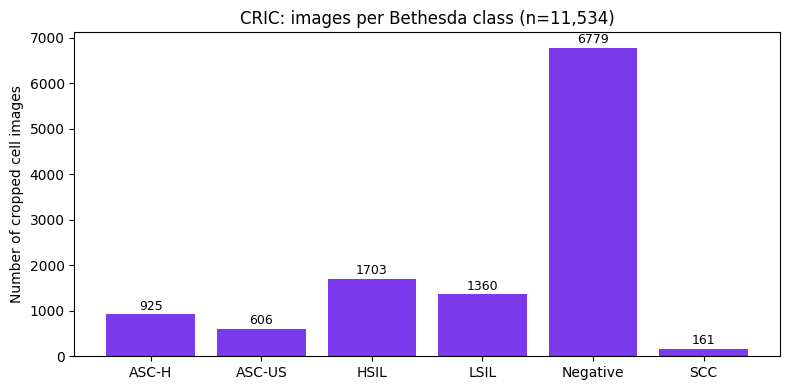

Class imbalance ratio (largest/smallest class): 42.1 to 1


In [1]:
import matplotlib.pyplot as plt

# Verified exact counts (train/val/test) from the acquisition notebook.
cric_counts = {
    "ASC-H": 925,
    "ASC-US": 606,
    "HSIL": 1703,
    "LSIL": 1360,
    "Negative": 6779,
    "SCC": 161,
}

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(cric_counts.keys(), cric_counts.values(), color="#7c3aed")
ax.set_title("CRIC: images per Bethesda class (n=11,534)")
ax.set_ylabel("Number of cropped cell images")
for i, v in enumerate(cric_counts.values()):
    ax.text(i, v + 100, str(v), ha="center", fontsize=9)
plt.tight_layout()
plt.savefig("cric_class_distribution.png", dpi=150)
plt.show()

print("Class imbalance ratio (largest/smallest class):",
      round(max(cric_counts.values()) / min(cric_counts.values()), 1), "to 1")

In [2]:
# TODO: fill these in from the box-derivation notebook's SIPAKMED_CLASS_DIRS /
# MENDELEY_CLASS_DIRS (a quick `{cls: len(os.listdir(path)) for cls, path in ...}`
# in a new Kaggle cell gives these without touching the long-running cell).

sipakmed_counts = {
    "Dyskeratotic": None,
    "Koilocytotic": None,
    "Metaplastic": None,
    "Parabasal": None,
    "Superficial-Intermediate": None,
}

mendeley_counts = {
    "Negative": None,
    "HSIL": None,
    "LSIL": None,
    "SCC": None,
}

for name, counts in [("SIPaKMeD", sipakmed_counts), ("Mendeley", mendeley_counts)]:
    if None in counts.values():
        print(f"{name}: counts not filled in yet — see TODO above.")
    else:
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.bar(counts.keys(), counts.values(), color="#7c3aed")
        ax.set_title(f"{name}: images per class")
        plt.xticks(rotation=20, ha="right")
        plt.tight_layout()
        plt.savefig(f"{name.lower()}_class_distribution.png", dpi=150)
        plt.show()

SIPaKMeD: counts not filled in yet — see TODO above.
Mendeley: counts not filled in yet — see TODO above.


## 2. Model architecture

Three CNN backbones are each fine-tuned in two stages: first on SIPaKMeD
(cell-type warm-start, backbone unfrozen), then separately on CRIC and on
Mendeley (severity grading, backbone unfrozen, new classification head).

**TODO before submitting:** confirm the exact optimizer used in
`model.compile(...)` in the training notebook — this table assumes Adam
since that's the Keras default and nothing in the notebook overrides it,
but that should be checked against the actual line, not assumed.

In [3]:
import pandas as pd

architecture_summary = pd.DataFrame([
    {"Model": "EfficientNetB0", "Framework": "Keras/TensorFlow",
     "Head": "GlobalAveragePooling2D -> Dense(num_classes, softmax)",
     "Activation (hidden)": "swish (built into EfficientNet blocks)",
     "Optimizer": "Adam (TODO: confirm)", "Learning rate": "1e-4",
     "Trainable params (SIPaKMeD stage)": "4,015,234 / 4,057,257"},
    {"Model": "ConvNeXtTiny", "Framework": "Keras/TensorFlow",
     "Head": "GlobalAveragePooling2D -> Dense(num_classes, softmax)",
     "Activation (hidden)": "GELU (ConvNeXt blocks)",
     "Optimizer": "Adam (TODO: confirm)", "Learning rate": "1e-4",
     "Trainable params (SIPaKMeD stage)": "TODO: pull from model.summary()"},
    {"Model": "RegNetY-400MF", "Framework": "PyTorch/torchvision",
     "Head": "AdaptiveAvgPool2d -> Linear(num_classes)",
     "Activation (hidden)": "ReLU",
     "Optimizer": "TODO: confirm (Adam or SGD)", "Learning rate": "1e-4",
     "Trainable params (SIPaKMeD stage)": "TODO: pull from training log"},
])
architecture_summary

,Model,Framework,Head,Activation (hidden),Optimizer,Learning rate,Trainable params (SIPaKMeD stage)
0,EfficientNetB0,Keras/TensorFlow,"GlobalAveragePooling2D -> Dense(num_classes, s...",swish (built into EfficientNet blocks),Adam (TODO: confirm),1e-4,"4,015,234 / 4,057,257"
1,ConvNeXtTiny,Keras/TensorFlow,"GlobalAveragePooling2D -> Dense(num_classes, s...",GELU (ConvNeXt blocks),Adam (TODO: confirm),1e-4,TODO: pull from model.summary()
2,RegNetY-400MF,PyTorch/torchvision,AdaptiveAvgPool2d -> Linear(num_classes),ReLU,TODO: confirm (Adam or SGD),1e-4,TODO: pull from training log


## 3. Initial performance metrics

Stage 1 (SIPaKMeD warm-start, all three architectures) is complete.
Stage 2 (severity fine-tuning on CRIC/Mendeley) has one of eight planned
runs done so far — EfficientNetB0 on CRIC.

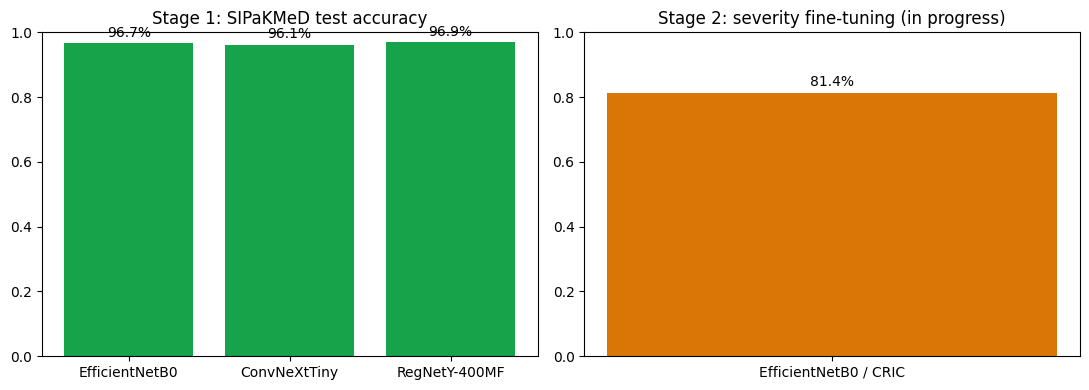

EfficientNetB0/CRIC per-class recall (weakest classes, from classification_report):
  SCC:     0.441
  ASC-US:  0.204
These being low is expected and notable: SCC and ASC-US are the rarest
classes in CRIC's training data, and per-class recall on SCC specifically
is the single most clinically important number in this project, since a
missed cancer-grade case can't be hidden inside an averaged accuracy score.


In [4]:
stage1_results = {"EfficientNetB0": 0.967, "ConvNeXtTiny": 0.961, "RegNetY-400MF": 0.969}
stage2_results = {"EfficientNetB0 / CRIC": 0.814}  # weighted F1: 0.810

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(stage1_results.keys(), stage1_results.values(), color="#16a34a")
axes[0].set_title("Stage 1: SIPaKMeD test accuracy")
axes[0].set_ylim(0, 1)
for i, v in enumerate(stage1_results.values()):
    axes[0].text(i, v + 0.02, f"{v:.1%}", ha="center")

axes[1].bar(stage2_results.keys(), stage2_results.values(), color="#d97706")
axes[1].set_title("Stage 2: severity fine-tuning (in progress)")
axes[1].set_ylim(0, 1)
for i, v in enumerate(stage2_results.values()):
    axes[1].text(i, v + 0.02, f"{v:.1%}", ha="center")

plt.tight_layout()
plt.savefig("initial_performance_metrics.png", dpi=150)
plt.show()

print("EfficientNetB0/CRIC per-class recall (weakest classes, from classification_report):")
print("  SCC:     0.441")
print("  ASC-US:  0.204")
print("These being low is expected and notable: SCC and ASC-US are the rarest")
print("classes in CRIC's training data, and per-class recall on SCC specifically")
print("is the single most clinically important number in this project, since a")
print("missed cancer-grade case can't be hidden inside an averaged accuracy score.")

## 4. Deployment option: Web interface + API (Swagger UI)

Delivered as a working MVP, not just a mockup screenshot:

- **API**: `backend/main.py` (FastAPI) — `POST /predict` takes an image,
  returns a severity grade with per-class confidence. Swagger UI is
  auto-generated at `/docs` once the server is running.
- **Web interface**: `frontend/index.html` — upload an image, calls the
  API, displays the result. Plain HTML/CSS/JS, no build step.
- **Status**: the interface and API contract are fully working end-to-end.
  The endpoint currently runs on a clearly-labeled placeholder predictor
  (the API response includes `"mock": true`) until the real
  `efficientnetb0_cric_final.keras` checkpoint is copied into `backend/`,
  at which point it switches to real predictions automatically.